# Accuracy Breakdown by Model

Overall, direct, and inferential accuracy for each model on the **occlusion** and **transparency** tests.

All results use **Combined** scoring: an answer counts as correct if either judge (GPT-5.4 or Claude Opus 4.6) marks it correct.

In [1]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [2]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

RESULTS_DIR = 'data/eval_results'
ANNOTATIONS_PATH = 'data/combined_output/annotations.json'

MODEL_STEMS = [
    'gpt-5.4',
    'claude-opus-4-6',
    'gemini-3.1-pro-preview',
    'Qwen3-VL-8B-Instruct',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c',
]

DISPLAY_NAMES = {
    'gpt-5.4': 'GPT-5.4',
    'claude-opus-4-6': 'Claude Opus 4.6',
    'gemini-3.1-pro-preview': 'Gemini 3.1 Pro',
    'Qwen3-VL-8B-Instruct': 'Qwen 3 VL 8B',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c': 'Llama 4 Maverick 17B',
}

JUDGE_MODELS = ['gpt-5.4', 'claude-opus-4-6']

import matplotlib as mpl

mpl.rcParams.update({
    'font.family':       'Arial',
    'font.size':         9,
    'axes.titlesize':    10,
    'axes.labelsize':    9,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'legend.fontsize':   9,
    'axes.titleweight':  'normal',
    'axes.grid':         False,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':        150,
})

import os
FIG_DIR = 'data/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', format='pdf')

In [3]:
# Load annotations for physical flag
with open(ANNOTATIONS_PATH) as f:
    annotations = json.load(f)

physical_map = {str(item['id']): item['physical'] for item in annotations}
physical_count = sum(physical_map.values())
print(f'Loaded {len(physical_map)} annotations — Direct: {physical_count}, Inferential: {len(physical_map) - physical_count}')

Loaded 378 annotations — Direct: 197, Inferential: 181


In [4]:
def compute_accuracy(judged_data, verdict_key, physical_map, judge_models):
    counts = {
        'overall':      [0.0, 0],
        'physical':     [0.0, 0],
        'non_physical': [0.0, 0],
    }
    for item in judged_data:
        verdict_dict = item.get(verdict_key, {})
        if not isinstance(verdict_dict, dict):
            continue
        scores = [verdict_dict[jm] for jm in judge_models
                  if jm in verdict_dict and verdict_dict[jm] is not None]
        if not scores:
            continue
        score = float(any(scores))
        item_id = str(item['id'])
        is_physical = physical_map.get(item_id)
        if is_physical is None:
            continue
        counts['overall'][0] += score;  counts['overall'][1] += 1
        if is_physical:
            counts['physical'][0] += score;  counts['physical'][1] += 1
        else:
            counts['non_physical'][0] += score;  counts['non_physical'][1] += 1
    return {k: (v[0] / v[1] * 100 if v[1] > 0 else None) for k, v in counts.items()}


judged_cache = {}
for stem in MODEL_STEMS:
    path = os.path.join(RESULTS_DIR, f'{stem}_judged_results.json')
    with open(path) as f:
        judged_cache[stem] = json.load(f)

rows = []
for stem in MODEL_STEMS:
    judged = judged_cache[stem]
    occ   = compute_accuracy(judged, 'occluded_correct',    physical_map, JUDGE_MODELS)
    trans = compute_accuracy(judged, 'transparent_correct', physical_map, JUDGE_MODELS)
    rows.append({
        'model':              DISPLAY_NAMES[stem],
        'occ_overall':        occ['overall'],
        'occ_physical':       occ['physical'],
        'occ_non_physical':   occ['non_physical'],
        'trans_overall':      trans['overall'],
        'trans_physical':     trans['physical'],
        'trans_non_physical': trans['non_physical'],
    })
df = pd.DataFrame(rows).set_index('model')
print('Data loaded.')


Data loaded.


---
## Summary Tables

In [5]:
col_labels = [
    'Occ: Overall', 'Occ: Direct', 'Occ: Inferential',
    'Trans: Overall', 'Trans: Direct', 'Trans: Inferential',
]
tbl = df.copy().round(1)
tbl.columns = col_labels
tbl = tbl.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A')
display(tbl)


/var/folders/8x/xp7b_zzn4gx4nk8_f1cqzlyc0000gn/T/ipykernel_60232/1522357694.py:7: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl = tbl.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A')


,Occ: Overall,Occ: Direct,Occ: Inferential,Trans: Overall,Trans: Direct,Trans: Inferential
model,,,,,,
GPT-5.4,49.5%,37.6%,62.4%,92.6%,91.9%,93.4%
Claude Opus 4.6,63.0%,51.8%,75.1%,89.4%,86.3%,92.8%
Gemini 3.1 Pro,79.4%,71.6%,87.8%,93.4%,94.4%,92.3%
Qwen 3 VL 8B,33.2%,20.9%,46.4%,89.7%,89.3%,90.1%
Llama 4 Maverick 17B,36.6%,31.6%,42.0%,88.6%,87.8%,89.5%


---
## Occlusion Test — Accuracy by Category

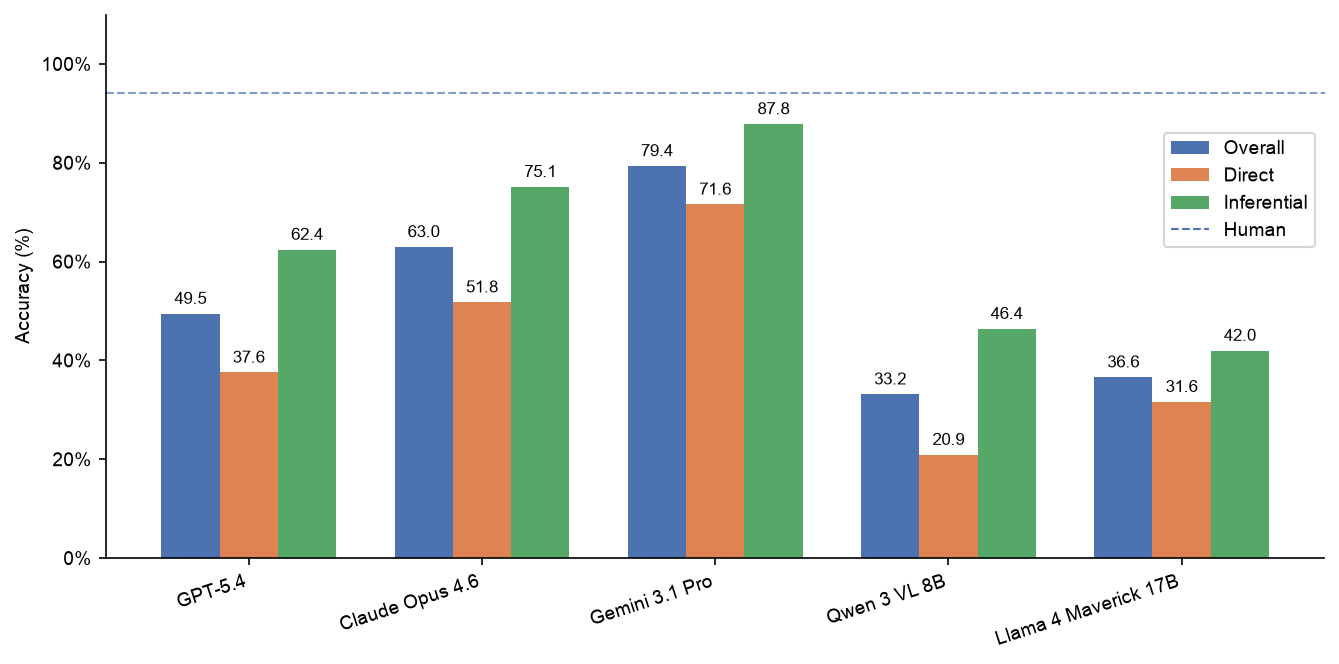

In [6]:
from matplotlib.lines import Line2D

models = list(DISPLAY_NAMES.values())
x = np.arange(len(models))
width = 0.25
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(9, 4.5))

for i, (col, label) in enumerate(zip(
    ['occ_overall', 'occ_physical', 'occ_non_physical'],
    ['Overall', 'Direct', 'Inferential']
)):
    bars = ax.bar(x + (i - 1) * width, df[col], width, label=label, color=colors[i])
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.1f}',
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8)
        
human_scores = {'Overall': 94.2}
for (label, score), color in zip(human_scores.items(), colors):
    ax.axhline(y=score, color=color, linestyle='--', linewidth=1, alpha=0.7,)
               #label=f'Human {label} ({score}%)')

#ax.set_title('Occlusion Accuracy')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=18, ha='right')
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Accuracy (%)')
#ax.legend()
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color=colors[0], linestyle='--', linewidth=1, label='Human'))
labels.append('Human')
ax.legend(handles=handles, labels=labels, loc='upper right', bbox_to_anchor=(1, 0.80))

plt.tight_layout()
save(fig, 'occ_accuracy')
plt.show()


---
## Occlusion Accuracy — Filtered to Transparent-Solvable Items

For each model, keep only items where at least one judge said the model answered the transparency test correctly.
This isolates whether occlusion — not ignorance — is the barrier.

In [7]:
def compute_accuracy_filtered(judged_data, occ_key, trans_key,
                               physical_map, score_judges, filter_mode):
    """
    filter_mode: 'and' or 'or'
    score_judges: list of judge model names used for occlusion scoring
    """
    JUDGE_GPT    = 'gpt-5.4'
    JUDGE_CLAUDE = 'claude-opus-4-6'

    counts = {
        'overall':      [0.0, 0, 0],
        'physical':     [0.0, 0, 0],
        'non_physical': [0.0, 0, 0],
    }
    for item in judged_data:
        trans_dict = item.get(trans_key, {})
        if not isinstance(trans_dict, dict):
            continue
        g = trans_dict.get(JUDGE_GPT)
        c = trans_dict.get(JUDGE_CLAUDE)

        if filter_mode == 'and':
            if not (g and c):
                continue
        elif filter_mode == 'or':
            if not (g or c):
                continue

        occ_dict = item.get(occ_key, {})
        if not isinstance(occ_dict, dict):
            continue
        occ_scores = [occ_dict[jm] for jm in score_judges
                      if jm in occ_dict and occ_dict[jm] is not None]
        if not occ_scores:
            continue
        occ_score = float(any(occ_scores))

        item_id = str(item['id'])
        is_physical = physical_map.get(item_id)
        if is_physical is None:
            continue

        counts['overall'][0] += occ_score
        counts['overall'][1] += round(occ_score)
        counts['overall'][2] += 1
        sub = 'physical' if is_physical else 'non_physical'
        counts[sub][0] += occ_score
        counts[sub][1] += round(occ_score)
        counts[sub][2] += 1

    return {k: (v[0]/v[2]*100 if v[2]>0 else None, v[1], v[2])
            for k, v in counts.items()}


FILTER_CONFIG = (JUDGE_MODELS, 'or')

filtered_dfs = {}
filtered_count_dfs = {}

for config_name, (score_judges, filter_mode) in [('Transparent-Solvable', FILTER_CONFIG)]:
    rows_acc, rows_cnt = [], []
    for stem in MODEL_STEMS:
        judged = judged_cache[stem]
        res = compute_accuracy_filtered(
            judged, 'occluded_correct', 'transparent_correct',
            physical_map, score_judges, filter_mode
        )
        rows_acc.append({
            'model':        DISPLAY_NAMES[stem],
            'overall':      res['overall'][0],
            'physical':     res['physical'][0],
            'non_physical': res['non_physical'][0],
        })
        rows_cnt.append({
            'model':        DISPLAY_NAMES[stem],
            'overall':      str(res['overall'][1]) + '/' + str(res['overall'][2]),
            'physical':     str(res['physical'][1]) + '/' + str(res['physical'][2]),
            'non_physical': str(res['non_physical'][1]) + '/' + str(res['non_physical'][2]),
        })
    filtered_dfs[config_name]       = pd.DataFrame(rows_acc).set_index('model')
    filtered_count_dfs[config_name] = pd.DataFrame(rows_cnt).set_index('model')

print('Done.')


Done.


In [8]:
cat_labels = ['Overall', 'Direct', 'Inferential']
cat_keys   = ['overall', 'physical', 'non_physical']

acc_df = filtered_dfs['Transparent-Solvable']
cnt_df = filtered_count_dfs['Transparent-Solvable']
combined = {}
for label, key in zip(cat_labels, cat_keys):
    combined[label] = [
        '{:.1f}%  ({})'.format(acc, cnt) if acc is not None else 'N/A'
        for acc, cnt in zip(acc_df[key], cnt_df[key])
    ]
tbl = pd.DataFrame(combined, index=acc_df.index)
display(tbl)


,Overall,Direct,Inferential
model,,,
GPT-5.4,52.3% (183/350),40.3% (73/181),65.1% (110/169)
Claude Opus 4.6,67.8% (229/338),57.1% (97/170),78.6% (132/168)
Gemini 3.1 Pro,80.7% (285/353),73.7% (137/186),88.6% (148/167)
Qwen 3 VL 8B,35.5% (120/338),22.9% (40/175),49.1% (80/163)
Llama 4 Maverick 17B,40.4% (135/334),34.9% (60/172),46.3% (75/162)


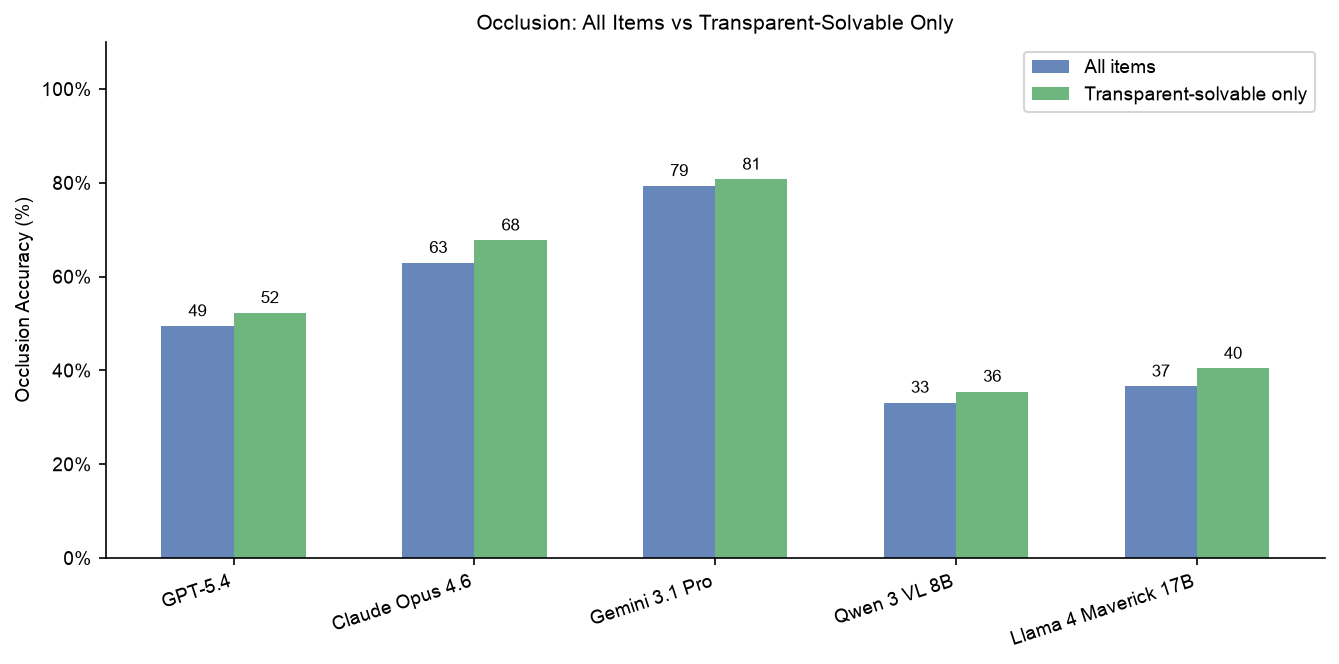

In [9]:
models = list(DISPLAY_NAMES.values())
x = np.arange(len(models))
width = 0.3

fdf = filtered_dfs['Transparent-Solvable']

fig, ax = plt.subplots(figsize=(9, 4.5))

bars1 = ax.bar(x - width/2, df['occ_overall'], width,
               label='All items',                 color='#4C72B0', alpha=0.85)
bars2 = ax.bar(x + width/2, fdf['overall'],    width,
               label='Transparent-solvable only', color='#55A868', alpha=0.85)
for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate('{:.0f}'.format(h),
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8)
ax.set_title('Occlusion: All Items vs Transparent-Solvable Only')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=18, ha='right')
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Occlusion Accuracy (%)')
ax.legend()

plt.tight_layout()
save(fig, 'filtered_overall')
plt.show()


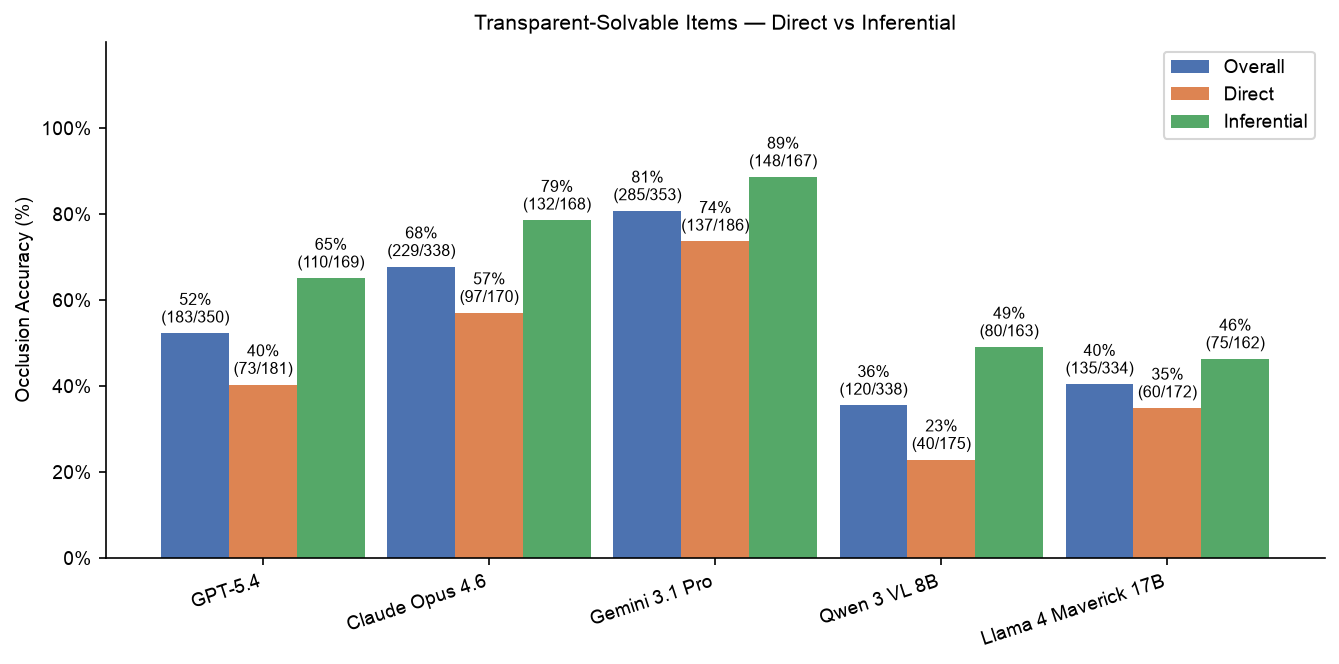

In [10]:
bar_colors = ['#4C72B0', '#DD8452', '#55A868']
cat_cols    = ['overall', 'physical', 'non_physical']
cat_labels2 = ['Overall', 'Direct', 'Inferential']

fdf = filtered_dfs['Transparent-Solvable']

fig, ax = plt.subplots(figsize=(9, 4.5))

for i, (col, label, color) in enumerate(zip(cat_cols, cat_labels2, bar_colors)):
    bars = ax.bar(x + (i - 1) * width, fdf[col], width, label=label, color=color)
    cnt_col = filtered_count_dfs['Transparent-Solvable'][col]
    for bar, cnt in zip(bars, cnt_col):
        h = bar.get_height()
        ax.annotate('{:.0f}%\n({})'.format(h, cnt),
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=7.5)
ax.set_title('Transparent-Solvable Items — Direct vs Inferential')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=18, ha='right')
ax.set_ylim(0, 120)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Occlusion Accuracy (%)')
ax.legend()

plt.tight_layout()
save(fig, 'filtered_phys_nonphys')
plt.show()


---
## Thinking Models — Accuracy Breakdown

Same analysis for **thinking/reasoning mode** variants of GPT-5.4 and Claude Opus 4.6 (`data/eval_results_thinking`).
All results use Combined scoring.


In [11]:
THINKING_DIR = 'data/eval_results_thinking'
THINKING_STEMS = ['gpt-5.4', 'claude-opus-4-6']
THINKING_DISPLAY = {
    'gpt-5.4':         'GPT-5.4 (thinking)',
    'claude-opus-4-6': 'Claude Opus 4.6 (thinking)',
}

thinking_cache = {}
for stem in THINKING_STEMS:
    path = os.path.join(THINKING_DIR, f'{stem}_judged_results.json')
    with open(path) as f:
        thinking_cache[stem] = json.load(f)

rows = []
for stem in THINKING_STEMS:
    judged = thinking_cache[stem]
    occ   = compute_accuracy(judged, 'occluded_correct',    physical_map, JUDGE_MODELS)
    trans = compute_accuracy(judged, 'transparent_correct', physical_map, JUDGE_MODELS)
    rows.append({
        'model':              THINKING_DISPLAY[stem],
        'occ_overall':        occ['overall'],
        'occ_physical':       occ['physical'],
        'occ_non_physical':   occ['non_physical'],
        'trans_overall':      trans['overall'],
        'trans_physical':     trans['physical'],
        'trans_non_physical': trans['non_physical'],
    })
thinking_df = pd.DataFrame(rows).set_index('model')
print('Thinking data loaded.')


Thinking data loaded.


### Summary Tables — Thinking Models

In [12]:
tbl = thinking_df.copy().round(1)
tbl.columns = col_labels
tbl = tbl.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A')
display(tbl)


/var/folders/8x/xp7b_zzn4gx4nk8_f1cqzlyc0000gn/T/ipykernel_60232/196252828.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl = tbl.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A')


,Occ: Overall,Occ: Direct,Occ: Inferential,Trans: Overall,Trans: Direct,Trans: Inferential
model,,,,,,
GPT-5.4 (thinking),66.2%,51.8%,82.0%,94.2%,93.4%,95.0%
Claude Opus 4.6 (thinking),57.9%,44.7%,72.4%,89.7%,86.8%,92.8%


### Thinking vs Base — Occlusion & Transparency Overall Accuracy

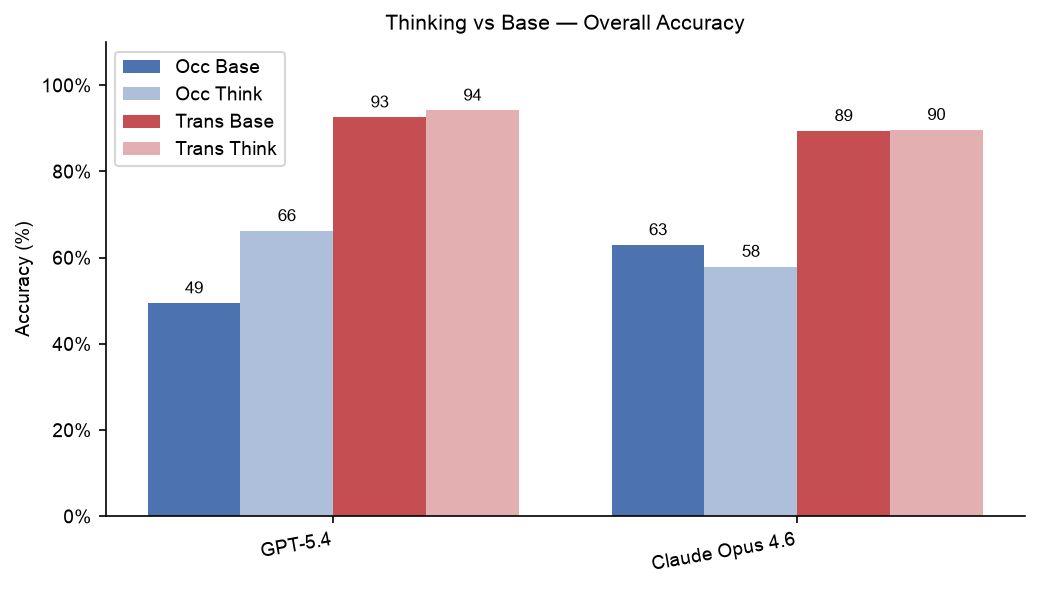

In [13]:
stems_pair  = ['gpt-5.4', 'claude-opus-4-6']
pair_labels = [DISPLAY_NAMES[s] for s in stems_pair]
x2 = np.arange(len(stems_pair))
w  = 0.2

bar_configs = [
    ('occ_overall',   'Occ Base',    '#4C72B0', 1.0,  df),
    ('occ_overall',   'Occ Think',   '#4C72B0', 0.45, thinking_df),
    ('trans_overall', 'Trans Base',  '#C44E52', 1.0,  df),
    ('trans_overall', 'Trans Think', '#C44E52', 0.45, thinking_df),
]

fig, ax = plt.subplots(figsize=(7, 4))

offsets = [-1.5*w, -0.5*w, 0.5*w, 1.5*w]
for offset, (col, label, color, alpha, src_df) in zip(offsets, bar_configs):
    if src_df is thinking_df:
        vals = [src_df.loc[THINKING_DISPLAY[s], col] for s in stems_pair]
    else:
        vals = [src_df.loc[DISPLAY_NAMES[s], col] for s in stems_pair]
    bars = ax.bar(x2 + offset, vals, w, label=label, color=color, alpha=alpha)
    for bar in bars:
        h = bar.get_height()
        if h is not None:
            ax.annotate(f'{h:.0f}', xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8)

ax.set_title('Thinking vs Base — Overall Accuracy')
ax.set_xticks(x2)
ax.set_xticklabels(pair_labels, rotation=10, ha='right')
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Accuracy (%)')
ax.legend()

plt.tight_layout()
save(fig, 'thinking_vs_base_overall')
plt.show()


### Thinking vs Base — Direct / Inferential Breakdown (Occlusion)

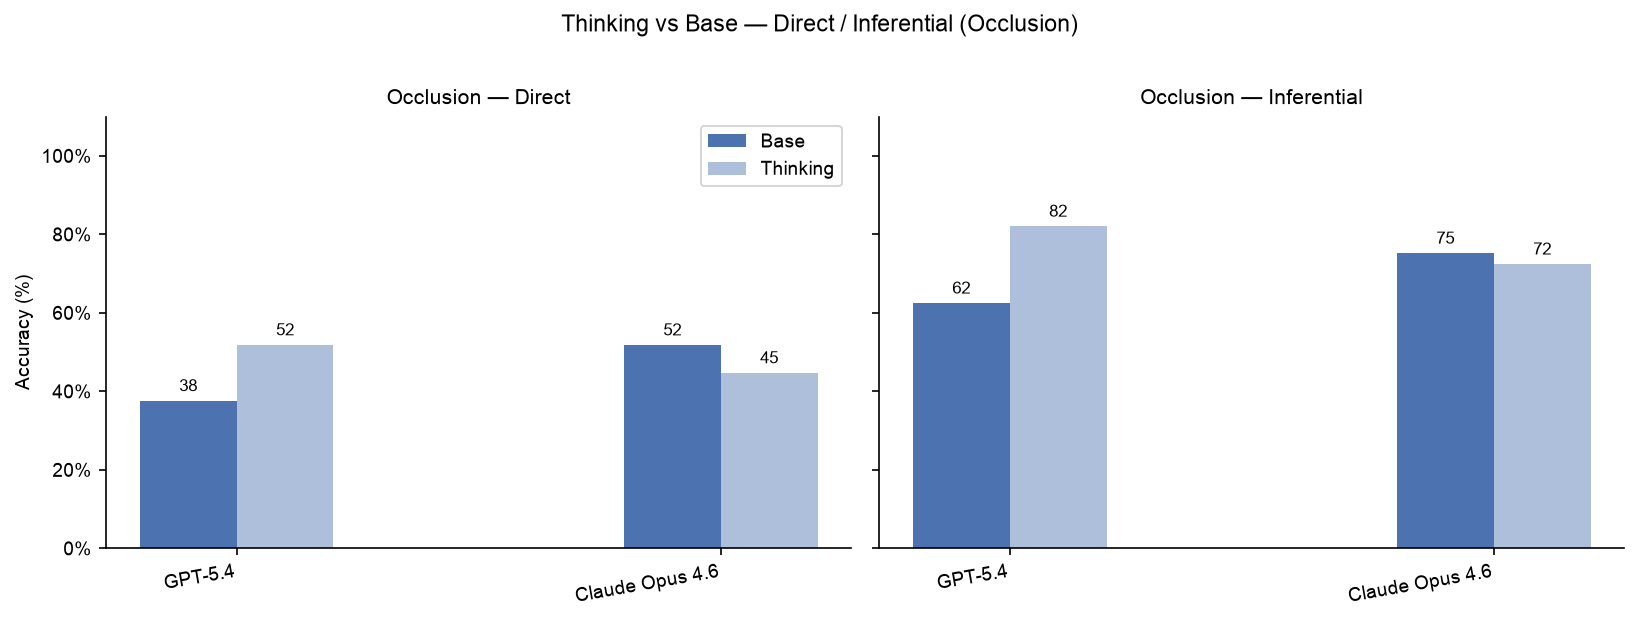

In [14]:
cat_pairs = [
    ('occ_physical',     'Occlusion — Direct'),
    ('occ_non_physical', 'Occlusion — Inferential'),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, (col, title) in zip(axes, cat_pairs):
    base_vals  = [df.loc[DISPLAY_NAMES[s], col]             for s in stems_pair]
    think_vals = [thinking_df.loc[THINKING_DISPLAY[s], col] for s in stems_pair]
    bars1 = ax.bar(x2 - w/2, base_vals,  w, label='Base',     color='#4C72B0')
    bars2 = ax.bar(x2 + w/2, think_vals, w, label='Thinking', color='#4C72B0', alpha=0.45)
    for bars in [bars1, bars2]:
        for bar in bars:
            h = bar.get_height()
            if h is not None:
                ax.annotate(f'{h:.0f}', xy=(bar.get_x() + bar.get_width()/2, h),
                            xytext=(0, 3), textcoords='offset points',
                            ha='center', va='bottom', fontsize=8)
    ax.set_title(title)
    ax.set_xticks(x2)
    ax.set_xticklabels(pair_labels, rotation=10, ha='right')
    ax.set_ylim(0, 110)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    if ax == axes[0]:
        ax.set_ylabel('Accuracy (%)')
        ax.legend()

fig.suptitle('Thinking vs Base — Direct / Inferential (Occlusion)', y=1.02)
plt.tight_layout()
save(fig, 'thinking_vs_base_phys_nonphys')
plt.show()


### Thinking Models — Direct vs Inferential Breakdown (Occlusion & Transparency)

### Thinking — Transparent-Solvable Filter

In [15]:
thinking_filtered_dfs = {}
thinking_filtered_count_dfs = {}

for config_name, (score_judges, filter_mode) in [('Transparent-Solvable', FILTER_CONFIG)]:
    rows_acc, rows_cnt = [], []
    for stem in THINKING_STEMS:
        judged = thinking_cache[stem]
        res = compute_accuracy_filtered(
            judged, 'occluded_correct', 'transparent_correct',
            physical_map, score_judges, filter_mode
        )
        rows_acc.append({
            'model':        THINKING_DISPLAY[stem],
            'overall':      res['overall'][0],
            'physical':     res['physical'][0],
            'non_physical': res['non_physical'][0],
        })
        rows_cnt.append({
            'model':        THINKING_DISPLAY[stem],
            'overall':      str(res['overall'][1]) + '/' + str(res['overall'][2]),
            'physical':     str(res['physical'][1]) + '/' + str(res['physical'][2]),
            'non_physical': str(res['non_physical'][1]) + '/' + str(res['non_physical'][2]),
        })
    thinking_filtered_dfs[config_name]       = pd.DataFrame(rows_acc).set_index('model')
    thinking_filtered_count_dfs[config_name] = pd.DataFrame(rows_cnt).set_index('model')

acc_df = thinking_filtered_dfs['Transparent-Solvable']
cnt_df = thinking_filtered_count_dfs['Transparent-Solvable']
combined = {}
for label, key in zip(cat_labels, cat_keys):
    combined[label] = [
        '{:.1f}%  ({})'.format(acc, cnt) if acc is not None else 'N/A'
        for acc, cnt in zip(acc_df[key], cnt_df[key])
    ]
tbl = pd.DataFrame(combined, index=acc_df.index)
display(tbl)


,Overall,Direct,Inferential
model,,,
GPT-5.4 (thinking),68.6% (243/354),54.6% (100/183),83.6% (143/171)
Claude Opus 4.6 (thinking),61.4% (208/339),49.1% (84/171),73.8% (124/168)


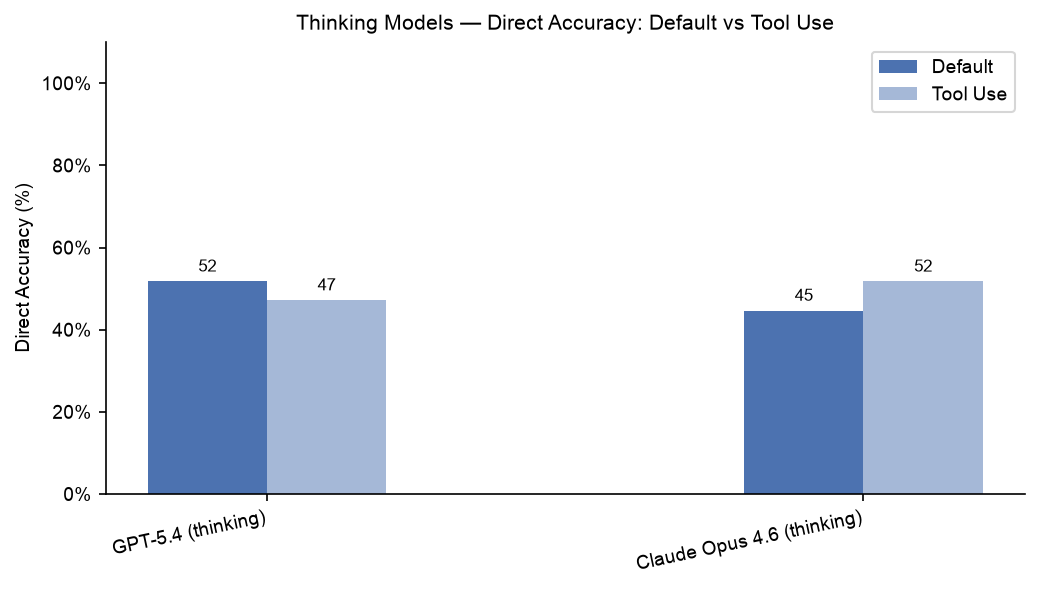

In [16]:
THINKING_TOOL_DIR = 'data/eval_results_tool_use_thinking'
thinking_tool_cache = {}
for stem in THINKING_STEMS:
    path = os.path.join(THINKING_TOOL_DIR, f'{stem}_judged_results.json')
    with open(path) as f:
        thinking_tool_cache[stem] = json.load(f)

rows = []
for stem in THINKING_STEMS:
    judged = thinking_tool_cache[stem]
    occ   = compute_accuracy(judged, 'occluded_correct',    physical_map, JUDGE_MODELS)
    trans = compute_accuracy(judged, 'transparent_correct', physical_map, JUDGE_MODELS)
    rows.append({
        'model':              THINKING_DISPLAY[stem],
        'occ_overall':        occ['overall'],
        'occ_physical':       occ['physical'],
        'occ_non_physical':   occ['non_physical'],
        'trans_overall':      trans['overall'],
        'trans_physical':     trans['physical'],
        'trans_non_physical': trans['non_physical'],
    })
thinking_tool_df = pd.DataFrame(rows).set_index('model')

think_labels = [THINKING_DISPLAY[s] for s in THINKING_STEMS]
x_t = np.arange(len(THINKING_STEMS))
w_t = 0.2

fig, ax = plt.subplots(figsize=(7, 4))

occ_default = [thinking_df.loc[THINKING_DISPLAY[s], 'occ_physical']      for s in THINKING_STEMS]
occ_tool    = [thinking_tool_df.loc[THINKING_DISPLAY[s], 'occ_physical'] for s in THINKING_STEMS]

bars1 = ax.bar(x_t - w_t/2, occ_default, w_t, label='Default',  color='#4C72B0')
bars2 = ax.bar(x_t + w_t/2, occ_tool,    w_t, label='Tool Use', color='#4C72B0', alpha=0.5)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        if h:
            ax.annotate(f'{h:.0f}', xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8)

ax.set_title('Thinking Models — Direct Accuracy: Default vs Tool Use')
ax.set_xticks(x_t)
ax.set_xticklabels(think_labels, rotation=12, ha='right')
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Direct Accuracy (%)')
ax.legend()

plt.tight_layout()
save(fig, 'thinking_tool_use')
plt.show()


---
## Few-Shot Prompting — Base vs Few-Shot Accuracy (Occlusion)

Comparison of occlusion accuracy with and without 2-shot prompting (examples: image 120 — bird wings, img1032 — dark mug).
No transparency test was run for the few-shot condition.

In [17]:
FEWSHOT_DIR = 'data/eval_results_fewshot'

fewshot_cache = {}
for stem in MODEL_STEMS:
    path = os.path.join(FEWSHOT_DIR, f'{stem}_judged_results.json')
    with open(path) as f:
        fewshot_cache[stem] = json.load(f)

rows = []
for stem in MODEL_STEMS:
    judged = fewshot_cache[stem]
    occ = compute_accuracy(judged, 'occluded_correct', physical_map, JUDGE_MODELS)
    rows.append({
        'model':            DISPLAY_NAMES[stem],
        'occ_overall':      occ['overall'],
        'occ_physical':     occ['physical'],
        'occ_non_physical': occ['non_physical'],
    })
fewshot_df = pd.DataFrame(rows).set_index('model')
print('Few-shot data loaded.')


Few-shot data loaded.


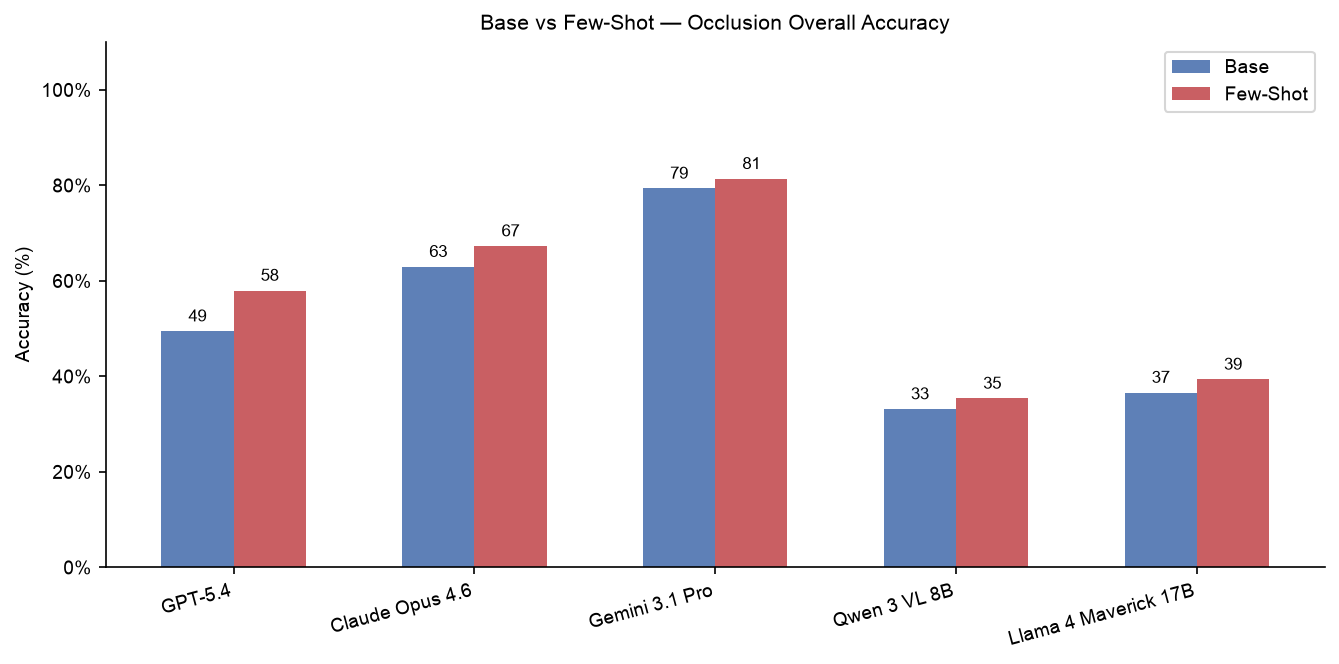

In [18]:
models = list(DISPLAY_NAMES.values())
x = np.arange(len(models))
w = 0.3

BASE_COLOR    = '#4C72B0'
FEWSHOT_COLOR = '#C44E52'

fig, ax = plt.subplots(figsize=(9, 4.5))

base_overall    = [df.loc[m, 'occ_overall']         for m in models]
fewshot_overall = [fewshot_df.loc[m, 'occ_overall'] for m in models]

bars1 = ax.bar(x - w/2, base_overall,    w, label='Base',     color=BASE_COLOR,    alpha=0.9)
bars2 = ax.bar(x + w/2, fewshot_overall, w, label='Few-Shot', color=FEWSHOT_COLOR, alpha=0.9)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        if h is not None:
            ax.annotate(f'{h:.0f}',
                        xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8)

ax.set_title('Base vs Few-Shot — Occlusion Overall Accuracy')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Accuracy (%)')
ax.legend()

plt.tight_layout()
save(fig, 'fewshot_overall')
plt.show()


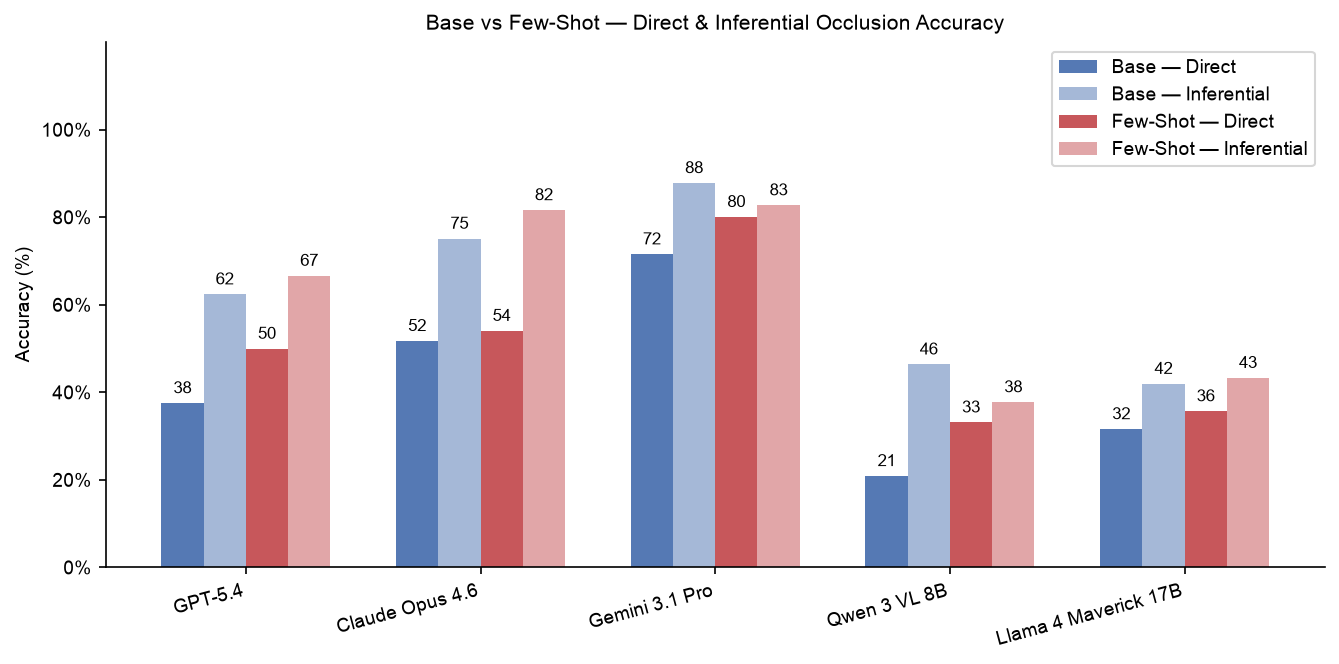

In [19]:
BASE_COLOR    = '#4C72B0'
FEWSHOT_COLOR = '#C44E52'

alphas = [0.95, 0.5]

n_bars = 4
group_width = 0.72
bar_w = group_width / n_bars
offsets = np.linspace(-group_width/2 + bar_w/2, group_width/2 - bar_w/2, n_bars)

configs = [
    (df,         'occ_physical',     BASE_COLOR,    alphas[0], 'Base — Direct'),
    (df,         'occ_non_physical', BASE_COLOR,    alphas[1], 'Base — Inferential'),
    (fewshot_df, 'occ_physical',     FEWSHOT_COLOR, alphas[0], 'Few-Shot — Direct'),
    (fewshot_df, 'occ_non_physical', FEWSHOT_COLOR, alphas[1], 'Few-Shot — Inferential'),
]

fig, ax = plt.subplots(figsize=(9, 4.5))

for (src_df, col, color, alpha, label), offset in zip(configs, offsets):
    vals = [src_df.loc[m, col] for m in models]
    bars = ax.bar(x + offset, vals, bar_w, label=label, color=color, alpha=alpha)
    for bar in bars:
        h = bar.get_height()
        if h is not None:
            ax.annotate(f'{h:.0f}',
                        xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8)

ax.set_title('Base vs Few-Shot — Direct & Inferential Occlusion Accuracy')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.set_ylim(0, 120)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Accuracy (%)')
ax.legend()

plt.tight_layout()
save(fig, 'fewshot_phys_nonphys')
plt.show()


In [20]:
tbl_fewshot = pd.DataFrame({
    'model': ['GPT-5.4', 'Claude Opus 4.6', 'Gemini 3.1 Pro', 'Qwen3-VL 8B', 'Llama-4 Maverick 17B'],
    'occ_overall': fewshot_df['occ_overall'].values,
    'occ_physical': fewshot_df['occ_physical'].values,
    'occ_non_physical': fewshot_df['occ_non_physical'].values,
}).set_index('model')

tbl_fewshot = tbl_fewshot.round(1)
tbl_fewshot.columns = ['Few-Shot Overall', 'Few-Shot Direct', 'Few-Shot Inferential']
tbl_fewshot = tbl_fewshot.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A')
display(tbl_fewshot)

/var/folders/8x/xp7b_zzn4gx4nk8_f1cqzlyc0000gn/T/ipykernel_60232/1931733992.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl_fewshot = tbl_fewshot.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A')


,Few-Shot Overall,Few-Shot Direct,Few-Shot Inferential
model,,,
GPT-5.4,58.0%,50.0%,66.7%
Claude Opus 4.6,67.3%,54.1%,81.7%
Gemini 3.1 Pro,81.4%,80.1%,82.8%
Qwen3-VL 8B,35.4%,33.2%,37.8%
Llama-4 Maverick 17B,39.4%,35.7%,43.3%
